# Correlation Matrix Heatmap

**Family:** Correlation &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Correlation:* Show the relationship between two or more variables.

## Design purpose

A grid that colors each cell by the correlation coefficient between a pair of variables. Strong positive and negative relationships across many variables stand out in one view.

## When to use

- Screen many numeric variables for pairwise relationships
- Spot multicollinearity before regression modelling
- Summarise a feature set in a report

## Avoid when

- Relationships are non-linear (Pearson r can miss them; check scatter plots)
- There are more than ~25 variables (cluster or filter first)

## Alternatives

- Pair plot
- Clustered heatmap with dendrogram

## Design tips

- Use a diverging palette centred at 0 with a neutral midpoint
- Show only the lower triangle to remove redundancy
- Annotate the coefficients when there are few variables

## Example

Correlations between the monthly returns of eight asset classes over 15 years (synthetic, factor-model data).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
pio.templates["vizlib"] = go.layout.Template(layout=dict(
    colorway=PALETTE, font=dict(family="Helvetica, Arial, sans-serif", size=13, color="#0b0b0b"),
    paper_bgcolor="#fcfcfb", plot_bgcolor="#fcfcfb", title=dict(x=0.02, xanchor="left"),
    xaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
    yaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
))
pio.templates.default = "plotly_white+vizlib"
pio.renderers.default = "plotly_mimetype+notebook_connected"

### Data

In [2]:
rng = np.random.default_rng(10)
n = 180  # months
equity, rates, infl = rng.normal(0, 1, (3, n))  # common risk factors
assets = {
    "US equities":   0.9 * equity + 0.3 * rng.normal(size=n),
    "Intl equities": 0.8 * equity + 0.5 * rng.normal(size=n),
    "EM equities":   0.7 * equity + 0.7 * rng.normal(size=n),
    "REITs":         0.6 * equity - 0.3 * rates + 0.6 * rng.normal(size=n),
    "High yield":    0.5 * equity - 0.2 * rates + 0.6 * rng.normal(size=n),
    "US Treasuries": -0.3 * equity - 0.9 * rates + 0.3 * rng.normal(size=n),
    "Gold":          -0.1 * equity + 0.5 * infl + 0.8 * rng.normal(size=n),
    "Commodities":   0.3 * equity + 0.7 * infl + 0.6 * rng.normal(size=n),
}
df = pd.DataFrame(assets)
title = "Correlation of monthly returns across asset classes"
corr = df.corr().round(2)
corr

,US equities,Intl equities,EM equities,REITs,High yield,US Treasuries,Gold,Commodities
US equities,1.00,0.75,0.73,0.62,0.55,-0.23,-0.05,0.25
Intl equities,0.75,1.00,0.63,0.53,0.53,-0.20,-0.12,0.11
EM equities,0.73,0.63,1.00,0.46,0.48,-0.24,-0.08,0.19
REITs,0.62,0.53,0.46,1.00,0.45,0.10,-0.05,0.22
High yield,0.55,0.53,0.48,0.45,1.00,0.03,-0.01,0.15
US Treasuries,-0.23,-0.20,-0.24,0.10,0.03,1.00,0.10,-0.02
Gold,-0.05,-0.12,-0.08,-0.05,-0.01,0.10,1.00,0.42
Commodities,0.25,0.11,0.19,0.22,0.15,-0.02,0.42,1.00


### Plot

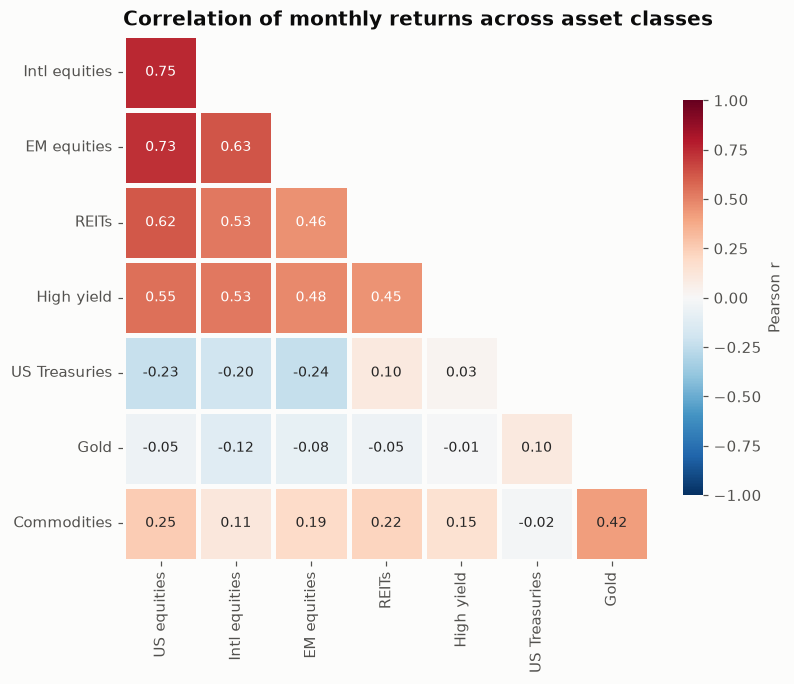

In [3]:
import seaborn as sns
mask = np.triu(np.ones_like(corr, dtype=bool))
# drop the all-masked first row / last column of the lower triangle
tri, tri_mask = corr.iloc[1:, :-1], mask[1:, :-1]
fig, ax = plt.subplots(figsize=(7.5, 6.2))
sns.heatmap(tri, mask=tri_mask, cmap=DIV_CMAP, vmin=-1, vmax=1, center=0, annot=True,
            fmt=".2f", annot_kws=dict(size=9), linewidths=2, linecolor="#fcfcfb",
            square=True, cbar_kws=dict(shrink=0.75, label="Pearson r"), ax=ax)
ax.grid(False)
ax.set_title(title)
fig.tight_layout()
plt.show()

## How to read it

Red cells are positive correlations and blue cells negative; darker means stronger. Equity markets move together, and REITs and high yield lean towards stocks. Treasuries are mildly negatively correlated with equities (about -0.2), which is why they diversify a stock portfolio; gold is roughly uncorrelated with everything except commodities.

## The same chart in other libraries

Each version uses the example data above. Pick the library that fits your stack: matplotlib/seaborn for static and print figures, plotly for interactive HTML, Altair for concise declarative specs.

### plotly

In [4]:
import plotly.express as px
lower = corr.where(np.tril(np.ones(corr.shape, dtype=bool), k=-1))
fig = px.imshow(lower, text_auto=".2f", color_continuous_scale="RdBu_r", zmin=-1, zmax=1,
                aspect="equal", title=title)
fig.update_layout(coloraxis_colorbar_title="Pearson r", height=560,
                  xaxis_showgrid=False, yaxis_showgrid=False)
fig.show()

## Try it with real data

**Source:** plotly.express.data.stocks() — weekly prices of six large US tech stocks, 2018–2019, bundled with plotly

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [5]:
import plotly.express as px
prices = px.data.stocks().set_index("date")
df = prices.pct_change().dropna()          # weekly returns
df.columns = [c.upper() for c in df.columns]
title = "Correlation of weekly returns, six tech stocks (2018-2019)"
corr = df.corr().round(2)
corr

,GOOG,AAPL,AMZN,FB,NFLX,MSFT
GOOG,1.00,0.43,0.61,0.50,0.50,0.71
AAPL,0.43,1.00,0.44,0.38,0.29,0.53
AMZN,0.61,0.44,1.00,0.55,0.63,0.71
FB,0.50,0.38,0.55,1.00,0.49,0.51
NFLX,0.50,0.29,0.63,0.49,1.00,0.55
MSFT,0.71,0.53,0.71,0.51,0.55,1.00


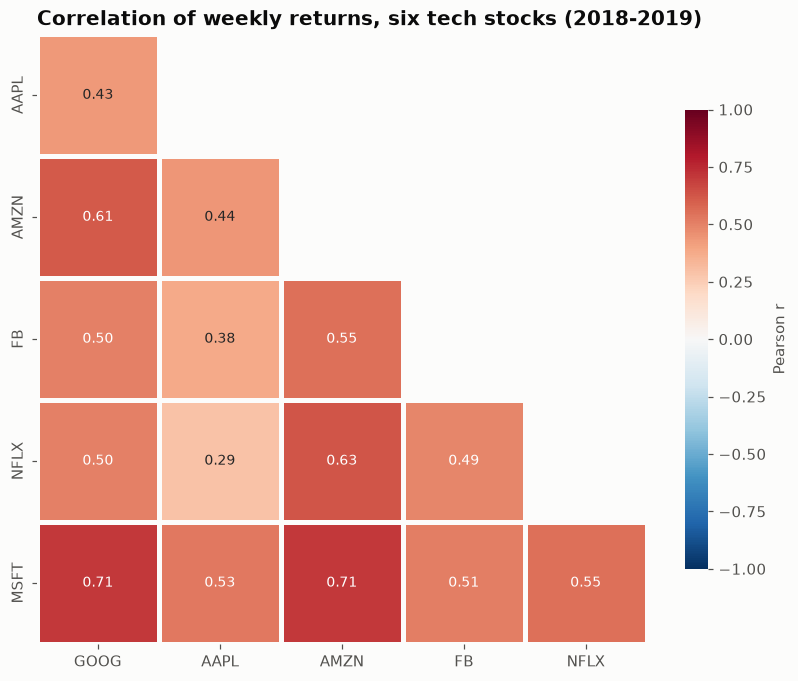

In [6]:
import seaborn as sns
mask = np.triu(np.ones_like(corr, dtype=bool))
# drop the all-masked first row / last column of the lower triangle
tri, tri_mask = corr.iloc[1:, :-1], mask[1:, :-1]
fig, ax = plt.subplots(figsize=(7.5, 6.2))
sns.heatmap(tri, mask=tri_mask, cmap=DIV_CMAP, vmin=-1, vmax=1, center=0, annot=True,
            fmt=".2f", annot_kws=dict(size=9), linewidths=2, linecolor="#fcfcfb",
            square=True, cbar_kws=dict(shrink=0.75, label="Pearson r"), ax=ax)
ax.grid(False)
ax.set_title(title)
fig.tight_layout()
plt.show()

---
Standalone script: [`correlation_heatmap.py`](correlation_heatmap.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)